# 공유자전거 대여 수요 예측 — 회귀 미니프로젝트

**모듈 1 ,  Day 1 ,  8교시 / TODO Notebook**

- 데이터: UCI Bike Sharing Dataset의 `hour.csv`
- 예측 대상: 시간당 총 대여량 `cnt`
- 개발 방법: **공통 코드 실행 → TODO 직접 구현 → CP-01~08 결과 확인**
- 이 Notebook은 *미완성 실습 템플릿*입니다. `...` 부분을 완성하기 전에는 일부 셀이 오류를 발생할 수 있습니다.
- 실습 안내 교안과 함께 사용합니다. TODO의 정답이나 모델 성능값은 제공하지 않습니다.
- VS Code에서 `ai-mini-projects/.venv`의 Python 3.11 커널을 선택합니다.
- **작업 폴더**: `mini-project-01/code/` (데이터 상대경로 `../data/hour.csv`)

> **주의**: Test 데이터는 최종 ⑧교시 평가에서만 사용합니다. 모든 코드는 ①부터 순서대로 실행합니다.

---
## ① 데이터 탐색 및 시각화 — CP-01
**문제:** 시간당 대여량을 예측하려면 한 행이 무엇을 기록하는지, 데이터에 빠진 값은 없는지, 대여량이 언제 크게 달라지는지 먼저 파악해야 한다.

### ①-1. 데이터 불러오기 — 공통 코드

`hour.csv`를 `df`에 불러온다. 한 행은 특정 날짜와 시간대의 기록이고, `cnt`는 그 시간대의 총 대여량이다.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"  # 그래프 한글 글꼴 설정
plt.rcParams["axes.unicode_minus"] = False  # 음수 기호 깨짐 방지

DATA_PATH = "../data/hour.csv"
df = pd.read_csv(DATA_PATH)
print("데이터 로딩 완료")

데이터 로딩 완료


### ①-2. 데이터 구조 및 품질 확인 — TODO

**확인 방법:** `shape`와 `dtypes`로 표의 크기와 자료형을, `head()`와 `describe()`로 실제 값과 범위를 확인한다. 결측값과 모든 열이 같은 중복 행도 각각 센다.

**방법:** 기초 통계로 값의 범위를 읽고, 결측과 중복은 별도로 검사해 값이 비어 있거나 기록이 반복됐는지 확인한다.

In [2]:
# TODO 1-1. 데이터의 행, 열 개수와 자료형을 확인합니다.

# shape: (행 개수, 열 개수)
# 결과: 17,379행, 17열
print("데이터 크기:", df.shape)


데이터 크기: (17379, 17)


In [3]:

# dtypes: 각 컬럼의 자료형 확인
# dteday는 문자열(str), 온도와 습도 등은 실수(float64)로 읽힘
print("\n자료형:\n", df.dtypes)



자료형:
 instant         int64
dteday            str
season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object


**결과 해석:** `(17379, 17)`은 기록 17,379개와 열 17개를 뜻한다.\
`dteday`는 문자열로 읽혔으므로 CP-02에서 날짜형으로 바꿔 시간순 분할에 사용한다.

In [4]:


# TODO 1-2. 처음 5개 행과 기초 통계량을 확인합니다.

# head(): 데이터의 처음 5개 행 확인
print("\n처음 5개 행:\n", df.head())



처음 5개 행:
    instant      dteday  season  yr  mnth  hr  holiday  weekday  workingday  \
0        1  2011-01-01       1   0     1   0        0        6           0   
1        2  2011-01-01       1   0     1   1        0        6           0   
2        3  2011-01-01       1   0     1   2        0        6           0   
3        4  2011-01-01       1   0     1   3        0        6           0   
4        5  2011-01-01       1   0     1   4        0        6           0   

   weathersit  temp   atemp   hum  windspeed  casual  registered  cnt  
0           1  0.24  0.2879  0.81        0.0       3          13   16  
1           1  0.22  0.2727  0.80        0.0       8          32   40  
2           1  0.22  0.2727  0.80        0.0       5          27   32  
3           1  0.24  0.2879  0.75        0.0       3          10   13  
4           1  0.24  0.2879  0.75        0.0       0           1    1  


In [5]:

# describe(): 숫자 컬럼의 평균, 최솟값, 최댓값 등 확인
print("\n전체 기초 통계량:\n", df.describe())



전체 기초 통계량:
           instant        season            yr          mnth            hr  \
count  17379.0000  17379.000000  17379.000000  17379.000000  17379.000000   
mean    8690.0000      2.501640      0.502561      6.537775     11.546752   
std     5017.0295      1.106918      0.500008      3.438776      6.914405   
min        1.0000      1.000000      0.000000      1.000000      0.000000   
25%     4345.5000      2.000000      0.000000      4.000000      6.000000   
50%     8690.0000      3.000000      1.000000      7.000000     12.000000   
75%    13034.5000      3.000000      1.000000     10.000000     18.000000   
max    17379.0000      4.000000      1.000000     12.000000     23.000000   

            holiday       weekday    workingday    weathersit          temp  \
count  17379.000000  17379.000000  17379.000000  17379.000000  17379.000000   
mean       0.028770      3.003683      0.682721      1.425283      0.496987   
std        0.167165      2.005771      0.465431      0.6

In [6]:

# cnt 컬럼만 선택해 대여량의 통계를 자세히 확인
# 결과: 시간당 평균 약 189.5대, 중앙값 142대
# 최소 1대, 최대 977대
print("\n대여량(cnt) 기초 통계량:\n", df["cnt"].describe())



대여량(cnt) 기초 통계량:
 count    17379.000000
mean       189.463088
std        181.387599
min          1.000000
25%         40.000000
50%        142.000000
75%        281.000000
max        977.000000
Name: cnt, dtype: float64


**결과 해석:** `50%`는 중앙값으로, 시간당 대여량의 가운데 값은 142대다.\
평균은 약 189.5대이고 최댓값은 977대이므로, 대여가 아주 많은 기록이 평균을 끌어올리는지 히스토그램에서 확인한다.

In [7]:


# TODO 1-3. 결측값과 중복 행 개수를 확인합니다.

# isna(): 값이 비어 있는지 확인
# sum(): 컬럼별로 비어 있는 값의 개수를 계산
# 결과: 모든 컬럼의 결측값이 0개
print("\n컬럼별 결측값:\n", df.isna().sum())



컬럼별 결측값:
 instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [8]:

# duplicated(): 모든 컬럼의 값이 같은 중복 행 확인
# 결과: 완전히 같은 중복 행이 0개
print("\n중복 행 개수:", df.duplicated().sum())


중복 행 개수: 0


**결과 해석:** 모든 열의 결측값과 완전히 같은 중복 행이 0개였다.\
날짜와 시간만 같은 기록이 있는지 확인하려면 `dteday`와 `hr` 두 열을 기준으로 따로 검사한다.

### ①-3. 가설과 탐색 방법 — TODO

- **가설:** 대여량은 시간대에 따라 달라지고, 출퇴근 무렵에 높을 수 있다.
- **탐색:** 히스토그램으로 대여량이 어느 구간에 몰려 있는지 확인한다. 같은 시간대의 기록을 모아 평균을 구하고, 하루 동안의 변화를 선 그래프로 본다.

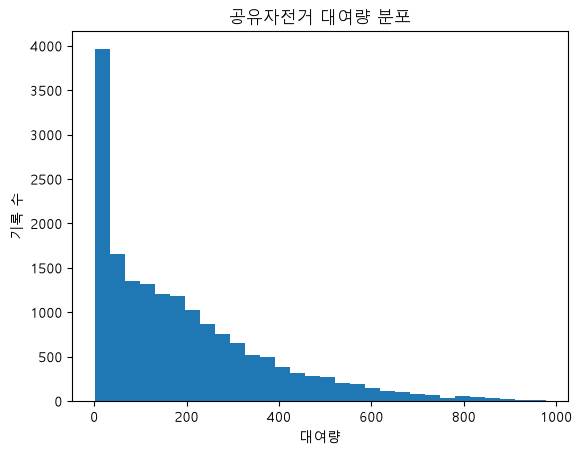

In [9]:
plt.hist(df["cnt"], bins=30)                   # 대여량을 30개 구간으로 나누어 히스토그램 그리기

plt.xlabel("대여량")                           # 가로축 이름
plt.ylabel("기록 수")                          # 세로축 이름
plt.title("공유자전거 대여량 분포")             # 그래프 제목
plt.show()                                    # 그래프 표시
#1시간 동안 자전거가 약 0~33대 대여된 기록이 약 4,000개 

**그래프 해석:** 가로축은 한 시간의 대여 대수, 막대 높이는 그 범위에 속한 기록 수다.\
낮은 대여량 구간에 기록이 많고 높은 대여량 쪽으로 꼬리가 길어서, 평균이 중앙값보다 높게 나온 결과와 연결된다.

In [10]:
# TODO 1-5. 시간대(hr)별 평균 대여량을 계산합니다.
hourly_mean = df.groupby("hr")["cnt"].mean()  # 시간대별로 기록을 묶어 평균 대여량 계산

print("시간대별 평균 대여량:\n", hourly_mean)    # 시간대와 계산된 평균 대여량 출력
# 자전거 대여량은 출퇴근 시간대(8시, 17~18시)에 높고 새벽에 가장 낮다.

시간대별 평균 대여량:
 hr
0      53.898072
1      33.375691
2      22.869930
3      11.727403
4       6.352941
5      19.889819
6      76.044138
7     212.064649
8     359.011004
9     219.309491
10    173.668501
11    208.143054
12    253.315934
13    253.661180
14    240.949246
15    251.233196
16    311.983562
17    461.452055
18    425.510989
19    311.523352
20    226.030220
21    172.314560
22    131.335165
23     87.831044
Name: cnt, dtype: float64


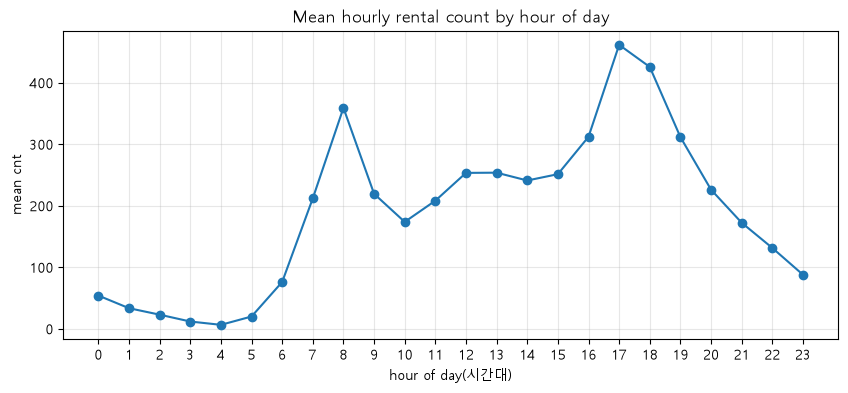

In [11]:
# [공통] 그래프 기본 설정
plt.figure(figsize=(10, 4)) # 그래프 크기 설정: 가로 10, 세로 4

# TODO 1-6. 시간대별 평균 대여량 선 그래프를 그립니다.
plt.plot(hourly_mean.index, hourly_mean.values, marker="o") # 시간대별 평균 대여량을 선과 점으로 표시

plt.xticks(range(0, 24))  # 가로축에 0시부터 23시까지 표시
plt.xlabel("hour of day(시간대)")
plt.ylabel("mean cnt")
plt.title("Mean hourly rental count by hour of day")
plt.grid(alpha=0.3)
plt.show() # 자전거 대여량은 출퇴근 시간대(8시, 17~18시)에 높고 새벽에 가장 낮다.

**그래프 해석:** 8시 평균은 약 359대, 17시는 약 461대, 18시는 약 426대로 높았고, 4시는 약 6대로 가장 낮았다.\
전체 기간의 평균이므로, 출퇴근과 관련된 패턴인지 보려면 Train에서 근무일과 휴일을 나눠 비교한다.

---
## ② 시간 순서 분할과 입력 특성 선택 — CP-02
**문제:** 미래 기록이나 대여가 끝나야 알 수 있는 값을 학습에 사용하면, 실제 예측보다 검증 성능이 좋게 보일 수 있다.

### ②-1. 시간 순서 분할 — TODO

**분할 방법:** 날짜순으로 정렬해 앞에서부터 약 70%를 Train, 다음 약 15%를 Validation, 나머지를 Test로 나눈다. 같은 날짜의 기록은 한 집합에만 둔다.

**사용 기준:** Train에서 학습하고, Validation에서 후보 모델을 비교한다. Test는 모델을 정한 뒤 최종 평가에 사용한다.

**방법:** 시간 순서 분할은 과거 기록으로 학습하고 그보다 뒤의 기록을 예측하는 상황을 재현한다.

In [12]:
# [공통] 날짜 변환 및 시간 순서 정렬
df["dteday"] = pd.to_datetime(df["dteday"])          # 날짜 문자열을 날짜 자료형으로 변환
df = df.sort_values(["dteday", "hr"]).reset_index(drop=True)  # 날짜, 시간순 정렬 후 행 번호를 다시 매김

dates = np.sort(df["dteday"].unique())               # 중복 없는 날짜를 시간순으로 정렬
n_dates = len(dates)                                 # 전체 날짜의 개수

# TODO 2-1. 날짜 기준 Train 약 70%, Validation 약 15%, 나머지 Test로 분할합니다.
# 같은 날짜의 행은 반드시 같은 집합에 포함되어야 합니다.
# 힌트: int(), 날짜 배열 슬라이싱, .isin()
n_train = int(n_dates * 0.7)                         # 전체 날짜 중 약 70%를 Train에 할당
n_valid = int(n_dates * 0.15)                        # 전체 날짜 중 약 15%를 Validation에 할당

train_dates = dates[:n_train]                        # 처음부터 Train 날짜 수만큼 선택
valid_dates = dates[n_train:n_train + n_valid]       # Train 이후부터 Validation 날짜 수만큼 선택
test_dates = dates[n_train + n_valid:]               # 나머지 날짜를 Test로 선택

train_df = df[df["dteday"].isin(train_dates)].copy()  # Train 날짜에 해당하는 행만 선택
valid_df = df[df["dteday"].isin(valid_dates)].copy()  # Validation 날짜에 해당하는 행만 선택
test_df = df[df["dteday"].isin(test_dates)].copy()    # Test 날짜에 해당하는 행만 선택

In [13]:
# 세 데이터 집합을 차례로 확인
for name, part in [
    ("Train", train_df),          # name에는 "Train", part에는 train_df가 들어감
    ("Validation", valid_df),     # 다음 반복에서는 Validation 데이터 확인
    ("Test", test_df),            # 마지막으로 Test 데이터 확인
]:
    print(name, part.shape)       # 집합 이름과 (행 개수, 열 개수) 출력
    print(part["dteday"].min(), "~", part["dteday"].max())  # 가장 이른 날짜와 늦은 날짜 출력
    print()

Train (12139, 17)
2011-01-01 00:00:00 ~ 2012-05-25 00:00:00

Validation (2616, 17)
2012-05-26 00:00:00 ~ 2012-09-11 00:00:00

Test (2624, 17)
2012-09-12 00:00:00 ~ 2012-12-31 00:00:00



**결과 해석:** Train 12,139행, Validation 2,616행, Test 2,624행이다.\
Train은 2012년 5월 25일까지, Validation은 5월 26일~9월 11일, Test는 9월 12일부터로 날짜가 겹치지 않는다.\
나눈 기준은 날짜라 행 수 비율이 정확히 70:15:15일 필요는 없고, 기간별 계절 차이는 이후 오차를 해석할 때 고려한다.

### ②-2. 데이터 누수 확인 — TODO

**확인할 가설:** 비회원 대여량(`casual`)과 회원 대여량(`registered`)의 합이 총 대여량(`cnt`)과 같을 수 있다.

**방법:** 각 행에서 합계와 `cnt`를 비교한 뒤 `.all()`로 모든 행이 일치하는지 검사한다.

In [14]:
# TODO 2-2. casual + registered == cnt가 모든 행에서 성립하는지 확인합니다.
same = (df["casual"] + df["registered"] == df["cnt"]).all()  # 모든 행이 같으면 True

print("데이터 관계 확인:", same)  # 모든 행에서 관계가 성립하는지 출력

# TODO (추가 확인). casual, registered, cnt의 상관관계를 비교해 봅니다.
correlation = df[["casual", "registered", "cnt"]].corr()  # 각 컬럼 쌍의 상관관계 계산

print("\n대여량 컬럼 간 상관관계:\n", correlation)  # 계산한 상관관계 표 출력

데이터 관계 확인: True

대여량 컬럼 간 상관관계:
               casual  registered       cnt
casual      1.000000    0.506618  0.694564
registered  0.506618    1.000000  0.972151
cnt         0.694564    0.972151  1.000000


**결과 해석:** `True`는 모든 행에서 회원과 비회원 대여량을 더하면 `cnt`가 된다는 뜻이다.\
상관표의 대각선 `1.0`은 같은 열끼리 비교한 값이고, `registered`와 `cnt` 사이의 `0.972`는 서로 다른 열의 값이다.\
회원, 비회원 대여량은 정답의 일부이자 예측 시점에 모르는 값이므로 둘 다 입력에서 뺀다.

### ②-3. 상관관계 분석 — TODO

**방법:** Train에서만 피어슨 상관계수를 계산해 두 값의 선형 관계를 −1에서 1 사이로 나타낸다. 히트맵은 방향과 강도를 색으로 보여준다.

In [15]:
# [공통] 분석에 사용할 컬럼
corr_cols = ["temp", "atemp", "hum", "windspeed", "cnt"]

# TODO 2-3. Train 데이터로만 상관계수를 계산합니다.
corr = train_df[corr_cols].corr()  # Train에서 선택한 컬럼들의 상관계수 계산
display(corr.round(3))

,temp,atemp,hum,windspeed,cnt
temp,1.000,0.992,-0.016,-0.015,0.398
atemp,0.992,1.000,-0.000,-0.058,0.398
hum,-0.016,-0.000,1.000,-0.297,-0.301
windspeed,-0.015,-0.058,-0.297,1.000,0.094
cnt,0.398,0.398,-0.301,0.094,1.000


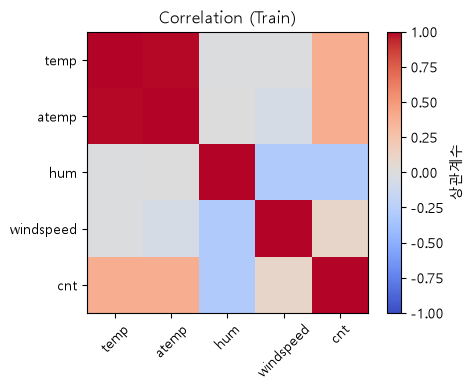

In [16]:
# [공통] 상관관계 시각화 기본 구조
plt.figure(figsize=(5, 4))

# TODO 2-4. 상관관계 행렬을 히트맵으로 시각화합니다.
# 힌트: plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
#       plt.colorbar(label="correlation")
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)  # 상관계수를 -1~1 범위의 색으로 표시
plt.colorbar(label="상관계수")                      # 색이 어떤 상관계수를 뜻하는지 표시

plt.xticks(range(len(corr_cols)), corr_cols, rotation=45)
plt.yticks(range(len(corr_cols)), corr_cols)
plt.title("Correlation (Train)")
plt.tight_layout()
plt.show()
# Train에서 기온, 체감온도는 대여량과 양의 상관관계
# 습도는 음의 상관관계, 풍속은 약한 선형 상관관계
# 기온과 체감온도의 상관계수는 0.992로 매우 높았다.
# 상관관계는 인과관계를 뜻하지 않으며, 낮은 상관계수만으로 특성을 제외하지 않는다.

**표와 히트맵 해석:** `cnt` 행을 보면 기온, 체감온도는 각각 `0.398`, 습도는 `−0.301`, 풍속은 `0.094`다.\
풍속과 대여량의 선형 관계는 약하지만, 이 값만으로 풍속을 뺄 근거는 부족하다.\
기온과 체감온도끼리는 `0.992`로 비슷하게 움직여, 하나만 사용해도 성능이 유지되는지 검증할 수 있다.

### ②-4. 입력 특성 선택 — TODO (핵심 의사결정 ①)

**선택 기준:** 예측 시점에 확보할 수 있는 시간, 달력, 날씨 특성을 사용하고, `cnt`는 정답으로 분리한다. `instant`는 행 식별자이고 `dteday`는 날짜 분할에 사용하므로 이번 입력에서 제외한다. 미래 날씨는 예보로 얻을 수 있다고 가정한다.

In [17]:
# TODO 2-5. 모델에 사용할 입력 컬럼을 선택합니다.
FEATURES = [
    "season",      # 계절
    "yr",          # 연도
    "mnth",        # 월
    "hr",          # 시간대
    "holiday",     # 공휴일 여부
    "weekday",     # 요일
    "workingday",  # 근무일 여부
    "weathersit",  # 날씨 상태
    "temp",        # 기온
    "atemp",       # 체감온도
    "hum",         # 습도
    "windspeed",   # 풍속
]
TARGET = "cnt"  # 예측할 정답: 시간당 총 대여량

print("사용할 특성:", FEATURES)  # 선택한 입력 특성 출력

사용할 특성: ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']


In [18]:
# [공통] 입력 X와 정답 y 분리
X_train = train_df[FEATURES].copy()
X_valid = valid_df[FEATURES].copy()
X_test = test_df[FEATURES].copy()

y_train = train_df[TARGET]
y_valid = valid_df[TARGET]
y_test = test_df[TARGET]

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_valid.shape, y_valid.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (12139, 12) (12139,)
Validation: (2616, 12) (2616,)
Test: (2624, 12) (2624,)


**결과 해석:** `X_train.shape`이 `(12139, 12)`이고 `y_train.shape`이 `(12139,)`이므로, 훈련 기록 12,139개 각각에 입력 12개와 정답 하나가 대응한다.\
Validation과 Test에서도 입력과 정답의 행 수가 각각 일치한다.

---
## ③ 특성공학 및 데이터 전처리 — CP-03
**문제:** 같은 8시라도 근무일과 휴일의 대여 패턴은 다를 수 있다. 시간대처럼 숫자가 범주를 가리키는 값과 기온처럼 크기를 나타내는 값은 의미에 맞게 처리한다.

### ③-1. 가설과 출퇴근 특성 — TODO

- **가설:** 시간대와 근무일 여부를 결합하면 출퇴근 수요 패턴을 모델에 직접 알려줄 수 있다.
- **실험:** 근무일이면서 7, 8, 9시 또는 17, 18, 19시면 `is_commute_hour`를 `1`로 표시하고, 그 외에는 `0`으로 표시한다. 예를 들어 근무일 8시는 `1`, 휴일 8시는 `0`이다.

**방법:** 시간대와 근무일 여부를 `AND` 조건으로 결합해, 두 조건이 모두 맞는 경우만 `1`로 만드는 특성공학이다.

In [19]:
# [공통] 실습에서 사용할 출퇴근 시간 가정
COMMUTE_HOURS = [7, 8, 9, 17, 18, 19]


def add_commute_feature(X):
    """기존 hr와 workingday로 is_commute_hour 특성을 추가합니다."""
    X = X.copy()

    # TODO 3-1. workingday == 1이면서 hr이 COMMUTE_HOURS에 있으면 1, 아니면 0
    # 근무일이고 출퇴근 시간대이면 1, 그 외에는 0을 새 컬럼에 저장
    X["is_commute_hour"] = (
        (X["workingday"] == 1) &               # 근무일인지 확인
        (X["hr"].isin(COMMUTE_HOURS))           # 출퇴근 시간 목록에 있는지 확인
    ).astype(int)                               # True는 1, False는 0으로 변환

    return X  # 새 컬럼이 추가된 데이터 반환


# [공통] 모든 집합에 같은 특성공학 함수 적용
X_train = add_commute_feature(X_train)
X_valid = add_commute_feature(X_valid)
X_test = add_commute_feature(X_test)

In [20]:
# [공통] 간단 검증 — 기대 결과는 [1, 0, 0, 1]
check = pd.DataFrame({"hr": [8, 8, 14, 18], "workingday": [1, 0, 1, 1]})
print(add_commute_feature(check))

   hr  workingday  is_commute_hour
0   8           1                1
1   8           0                0
2  14           1                0
3  18           1                1


**결과 해석:** `[1, 0, 0, 1]`에서 두 8시 기록의 값이 다른 이유는 근무일 여부가 다르기 때문이다.\
근무일 14시는 시간 조건을 만족하지 않아 `0`, 근무일 18시는 두 조건을 만족해 `1`이다.\
이 출력은 규칙이 제대로 작동하는지 확인한 결과다.

### ③-2. 특성 유형 구분 — TODO

**방법:** 숫자의 모양보다 의미를 기준으로 열을 분류한다. `hr`처럼 범주를 뜻하면 원-핫 인코딩, `temp`처럼 크기를 나타내면 표준화, `workingday`처럼 이미 0과 1로 표시된 값이면 그대로 사용한다.

In [21]:
# TODO 3-2. 선택한 입력 특성을 세 유형으로 구분합니다.
# 범주형(One-Hot 인코딩), 수치형(StandardScaler), 이진형(그대로 사용)
# ②교시 FEATURES와 새로 만든 is_commute_hour가 모두 포함되어야 합니다.
categorical_features = ["season", "mnth", "hr", "weekday", "weathersit"]  # 범주형
numeric_features = ["temp", "atemp", "hum", "windspeed"]                 # 수치형
binary_features = ["yr", "holiday", "workingday", "is_commute_hour"]     # 이진형

# [공통] 중복/누락 없는지 확인
all_features = categorical_features + numeric_features + binary_features
assert len(all_features) == len(set(all_features)), "특성 목록이 중복됩니다."
assert set(all_features) == set(X_train.columns), "분류되지 않은 컬럼이 있습니다."

print("범주형:", categorical_features)
print("수치형:", numeric_features)
print("이진형:", binary_features)

범주형: ['season', 'mnth', 'hr', 'weekday', 'weathersit']
수치형: ['temp', 'atemp', 'hum', 'windspeed']
이진형: ['yr', 'holiday', 'workingday', 'is_commute_hour']


**결과 해석:** 범주형 5개, 수치형 4개, 이진형 4개가 출력됐다.\
`assert`를 통과했으므로 출퇴근 특성을 포함한 Train 입력 13개가 중복이나 누락 없이 분류됐다.

### ③-3. 전처리 적용과 결과 확인

**방법:** `ColumnTransformer`로 원-핫 인코딩, 표준화, 그대로 통과시키기를 한 번에 적용한다.

`fit_transform(X_train)`에서 Train의 범주 목록과 평균, 표준편차를 학습한다. Validation에는 `transform()`으로 같은 기준을 적용해 검증 데이터가 전처리 기준을 바꾸지 않게 한다.

In [22]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer


def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            (
                "범주형",  # 이 변환에 붙이는 이름
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),  # 범주를 0과 1로 변환
                categorical_features,  # 변환할 범주형 컬럼 목록
            ),
            (
                "수치형",  # 이 변환에 붙이는 이름
                StandardScaler(),  # 수치형 컬럼을 표준화
                numeric_features,  # 변환할 수치형 컬럼 목록
            ),
            (
                "이진형",  # 이 변환에 붙이는 이름
                "passthrough",  # 값을 변환하지 않고 그대로 사용
                binary_features,  # 그대로 통과시킬 이진형 컬럼 목록
            ),
        ]
    )

preprocessor = make_preprocessor()  # 전처리 객체 생성

# Train으로 변환 기준을 학습하고 Train을 변환
Xt_train = preprocessor.fit_transform(X_train)

# Train에서 학습한 기준을 그대로 Validation에 적용
Xt_valid = preprocessor.transform(X_valid)

print("변환 전 Train:", X_train.shape, "→ 변환 후:", Xt_train.shape)
print()
print("변환 전 Valid:", X_valid.shape, "→ 변환 후:", Xt_valid.shape)

변환 전 Train: (12139, 13) → 변환 후: (12139, 59)

변환 전 Valid: (2616, 13) → 변환 후: (2616, 59)


In [23]:
# Train에서만 전처리 기준을 학습합니다.
Xt_train = preprocessor.fit_transform(X_train)
Xt_valid = preprocessor.transform(X_valid)

print("변환 전 Train:", X_train.shape, "→ 변환 후:", Xt_train.shape)
print()
print("변환 전 Valid:", X_valid.shape, "→ 변환 후:", Xt_valid.shape)

변환 전 Train: (12139, 13) → 변환 후: (12139, 59)

변환 전 Valid: (2616, 13) → 변환 후: (2616, 59)


**결과 해석:** 두 집합 모두 13개 열에서 59개 열로 바뀌고, 기록 수는 유지됐다.\
시간대처럼 여러 값을 가진 범주형 열이 여러 표시 열로 펼쳐지면서 열 수가 늘어난 것이다.

**다음 판단:** 열 수가 같아졌으므로 모델에 넣을 구조가 준비됐다.\
출퇴근 특성이 실제로 유용한지는 같은 모델에서 이 특성을 넣었을 때와 뺐을 때의 검증 성능을 비교한다.

---
## ④ 기준 모델과 선형 회귀 실험 — CP-04
**문제:** 시간, 날씨를 사용해 대여량을 예측하려면, 먼저 과거 평균만 사용했을 때보다 얼마나 나아지는지 확인해야 한다.

### ④-1. 가설과 실험 방법

- **가설:** 출퇴근 시간이나 날씨에 따라 수요가 달라진다면, 이런 정보를 사용하는 선형 회귀가 모든 시간에 평균을 예측하는 모델보다 검증 오차가 작을 것이다.
- **실험:** 기준 모델은 훈련 대여량의 평균을 모든 시간의 예측값으로 사용한다. 선형 회귀는 시간, 날씨 등 각 특성의 효과를 계수로 학습해 더한다. 두 모델은 같은 Train으로 학습하고 같은 Validation에서 비교한다.

**알고리즘:** 선형 회귀는 훈련 대여량과 예측값의 차이를 제곱해 더한 값이 가장 작아지도록 계수를 학습한다.

In [24]:
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

# TODO 4-1. 전처리와 기준 모델을 연결한다.
dummy_model = Pipeline([
    ("preprocessor", make_preprocessor()),       # CP-03에서 만든 전처리
    ("model", DummyRegressor(strategy="mean")),  # 훈련 대여량의 평균을 예측
])

# TODO 4-2. 전처리와 선형 회귀 모델을 연결한다.
linear_model = Pipeline([
    ("preprocessor", make_preprocessor()),  # CP-03에서 만든 전처리
    ("model", LinearRegression()),         # 선형 회귀 모델
])

# [공통] 모델 학습
dummy_model.fit(X_train, y_train)
linear_model.fit(X_train, y_train)
print("학습 완료")

학습 완료


**실행 확인:** `학습 완료`는 두 모델이 Train으로 학습됐다는 뜻이다.\
예측이 얼마나 맞는지는 아래 검증 결과표로 확인한다.

### ④-2. 평가 기준과 결과표

`summarize()`로 두 모델의 Train과 Validation 성능을 같은 지표로 계산한다. 모델 비교에서는 Validation MAE를 먼저 본다.

- **MAE:** 실제값과 예측값의 차이를 절댓값으로 바꿔 평균을 낸다. MAE가 50이면 한 시간당 대여량이 평균적으로 50대 차이 났다는 뜻이다.
- **RMSE:** 오차를 제곱해 큰 오차에 더 큰 비중을 두는 지표다. MAE와 RMSE는 낮을수록 좋다.
- **R²:** 같은 평가 데이터의 실제 평균으로 예측했을 때와 제곱오차를 비교한다. 1은 완벽한 예측, 0은 평균 예측과 같은 성능, 음수는 평균 예측보다 제곱오차가 크다는 뜻이다.

In [25]:
from sklearn.metrics import (
    mean_absolute_error,       # MAE 계산
    root_mean_squared_error,   # RMSE 계산
    r2_score,                  # R² 계산
)


def evaluate_regression(model, X, y):
    """모델의 MAE, RMSE, R²를 계산해 딕셔너리로 반환한다."""

    pred = model.predict(X)  # 입력 데이터 X로 대여량 예측

    return {
        "MAE": mean_absolute_error(y, pred),        # 실제값과 예측값의 평균 절대 오차
        "RMSE": root_mean_squared_error(y, pred),   # 큰 오차에 더 큰 비중을 두는 지표
        "R2": r2_score(y, pred),                   # 평균 예측과 비교한 결정계수
    }


def summarize(name, model):
    """하나의 모델에 대한 Train, Validation 평가 결과를 정리한다."""

    tr = evaluate_regression(model, X_train, y_train)  # Train 성능 계산
    va = evaluate_regression(model, X_valid, y_valid)  # Validation 성능 계산

    return {
        "Model": name,             # 모델 이름
        "Train MAE": tr["MAE"],    # 훈련 데이터의 MAE
        "Train RMSE": tr["RMSE"],  # 훈련 데이터의 RMSE
        "Train R2": tr["R2"],      # 훈련 데이터의 R²
        "Valid MAE": va["MAE"],    # 검증 데이터의 MAE
        "Valid RMSE": va["RMSE"],  # 검증 데이터의 RMSE
        "Valid R2": va["R2"],      # 검증 데이터의 R²
    }

In [26]:
# [공통] 이후 교시에서 결과를 누적할 리스트
results = []
results.append(summarize("DummyRegressor", dummy_model))
results.append(summarize("LinearRegression", linear_model))

# TODO 4-4. 두 모델의 성능을 DataFrame으로 비교합니다.
results_df = pd.DataFrame(results).round(3)  # 결과를 표로 만들고 소수점 셋째 자리까지 표시
display(results_df)                         # 비교표 출력

,Model,Train MAE,Train RMSE,Train R2,Valid MAE,Valid RMSE,Valid R2
0,DummyRegressor,119.572,152.40,0.000,194.109,253.892,-0.296
1,LinearRegression,55.334,73.41,0.768,99.854,124.008,0.691


**결과:** Validation MAE는 기준 모델 194.109대에서 선형 회귀 99.854대로 줄었다.\
같은 검증 기간에 시간당 평균 절대 오차를 94.255대 줄였으므로, 이 실험에서는 시간, 날씨 같은 특성을 사용한 예측이 기준 모델보다 나았다.

**기준 모델의 R²가 음수인 이유:** 기준 모델은 Train 대여량의 평균으로 예측한다.\
Validation R²의 비교 기준은 Validation 대여량의 실제 평균이므로, 기준 모델의 Validation R²도 음수(-0.296)가 될 수 있다.

**훈련, 검증 차이:** 선형 회귀의 MAE는 Train 55.334대, Validation 99.854대로 44.520대 차이가 났다.\
훈련 기록에 치우쳤을 가능성은 있지만, 두 기간의 계절과 수요 패턴도 다르므로 이 차이만으로 과대적합을 확정하지 않는다.

**선형 회귀의 한계와 다음 실험:** 현재 모델은 특성별 효과를 더한다.\
예를 들어 기온이 높을 때만 습도의 영향이 커지는 관계는 두 특성을 조합하지 않으면 표현하기 어렵다.\
CP-05에서는 조건에 따라 데이터를 나누는 결정 트리로 검증 오차가 줄어드는지 확인한다.

---
## ⑤ 결정 트리 실험 — CP-05
**문제:** 결정 트리는 조건을 나눠 대여량을 예측한다. 몇 단계까지 나눠야 새로운 기간의 대여량도 잘 예측하는지 확인한다.

### ⑤-1. 가설과 실험 방법

- **가설:** 얕은 트리는 수요 패턴을 충분히 구분하지 못할 수 있다. 깊은 트리는 훈련 오차를 줄일 수 있지만, 훈련 기록에 지나치게 맞으면 검증 오차가 커질 수 있다.
- **실험:** `max_depth`를 3, 6, 12, 15, 20, 제한 없음으로 바꾼다. 같은 Train 데이터로 학습하고, 같은 Validation 기간에서 오차를 비교한다.

**알고리즘:** 회귀 결정 트리는 훈련 오차가 줄어드는 조건으로 기록을 반복해서 나누고, 마지막 그룹의 평균 대여량을 예측한다.

In [27]:
from sklearn.tree import DecisionTreeRegressor

# [공통] 실험 설정 및 저장 구조
depths = [3, 6, 12, 15, 20, None]  # 최대 깊이 후보, None은 깊이 제한 없음
tree_models = {}
tree_results = []

# TODO 5-1~5-3. 각 깊이별 Pipeline 생성, 학습, 평가 결과 수집
for d in depths:
    # TODO 5-1. 전처리 + DecisionTreeRegressor(max_depth=d, random_state=42)
    model = Pipeline([
        ("preprocessor", make_preprocessor()),  # CP-03에서 만든 전처리
        ("model", DecisionTreeRegressor(
            max_depth=d,      # 이번 반복에서 사용할 트리 깊이
            random_state=42,  # 같은 조건에서 결과를 재현하기 위한 설정
        )),
    ])

    # TODO 5-2. 모델 학습
    model.fit(X_train, y_train)

    # [공통] 학습한 모델 보관
    tree_models[d] = model

    # TODO 5-3. summarize()로 성능 결과 수집
    row = summarize(f"DecisionTree_depth_{d}", model)
    tree_results.append(row)  # 결정 트리끼리 비교할 결과에 추가

# 깊이별 결과를 표로 만들어 다음 셀에서 사용한다.
tree_df = pd.DataFrame(tree_results)
tree_df["max_depth"] = depths

### ⑤-2. 실험 결과와 판단

표에서 깊이별 오차를 비교하고, 그래프에서 Train MAE가 줄어드는 동안 Validation MAE도 함께 줄었는지 확인한다.

In [28]:
# 깊이별로 훈련 오차와 검증 오차를 비교한다.
tree_table = tree_df[["Train MAE", "Valid MAE", "Valid RMSE"]].copy()
tree_table.insert(0, "최대 깊이", ["제한 없음" if d is None else str(d) for d in depths])
display(tree_table.round(3))

,최대 깊이,Train MAE,Valid MAE,Valid RMSE
0,3,82.785,158.976,194.181
1,6,62.340,120.455,160.465
2,12,32.297,107.288,161.604
3,15,21.628,101.432,157.598
4,20,9.610,110.955,174.651
5,제한 없음,0.012,99.455,153.082


**표 읽기:** 한 행은 최대 깊이 하나의 결과다.\
같은 깊이에서 Train과 Validation MAE를 비교하고, 아래 그래프에서 깊이를 바꿨을 때 두 오차가 같은 방향으로 움직이는지 본다.

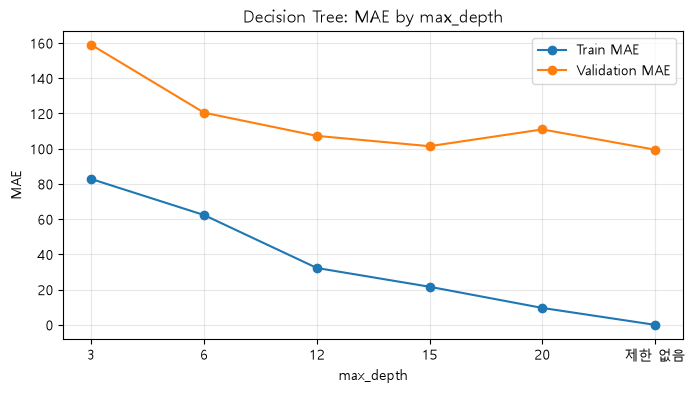

In [29]:
positions = list(range(len(depths)))

# None은 숫자 깊이가 아니므로 "제한 없음"으로 표시한다.
depth_labels = [
    str(depth) if depth is not None else "제한 없음"
    for depth in depths
]

# TODO 5-4. 깊이별 Train MAE와 Validation MAE를 각각 선 그래프로 표시합니다.
# # 실험 설정마다 그래프의 가로 위치를 하나씩 만든다.

# 그래프 크기 설정
plt.figure(figsize=(8, 4))

# 깊이별 Train MAE를 선과 점으로 표시한다.
plt.plot(
    positions,
    tree_df["Train MAE"],
    marker="o",
    label="Train MAE",
)

# 깊이별 Validation MAE를 선과 점으로 표시한다.
plt.plot(
    positions,
    tree_df["Valid MAE"],
    marker="o",
    label="Validation MAE",
)

plt.xticks(positions, depth_labels)              # 각 위치에 깊이 설정 표시
plt.xlabel("max_depth")                          # 가로축 이름
plt.ylabel("MAE")                               # 세로축 이름
plt.title("Decision Tree: MAE by max_depth")       # 그래프 제목
plt.legend()                                   # 선이 무엇을 뜻하는지 표시
plt.grid(alpha=0.3)                             # 연한 격자 표시
plt.show()                                     # 그래프 출력

**깊이에 따른 변화:** 깊이 3 → 15에서는 Validation MAE가 158.976 → 101.432대로 줄었다.\
깊이 15 → 20에서는 Train MAE가 21.628 → 9.610대로 줄었지만, Validation MAE는 101.432 → 110.955대로 오히려 늘었다.\
이 구간은 훈련 성능 개선이 새 데이터로 이어지지 않은 사례다.

**후보와 한계:** 깊이 제한이 없는 트리는 Validation MAE가 99.455대로 트리 중 가장 낮아 MAE 기준의 후보다.\
Train MAE는 0.012대로 거의 0이어서, 훈련 기록에 지나치게 맞았을 가능성을 살펴본다.\
훈련과 검증 기간이 다르므로 오차 차이만으로 과대적합을 단정하지 않는다.

**선형 회귀와 비교:** 깊이 제한이 없는 트리는 Validation MAE가 선형 회귀보다 0.399대 낮았다.\
반면 큰 오차에 더 민감한 Validation RMSE는 선형 회귀가 124.008대로 트리의 153.082대보다 낮았다.\
평균 오차의 차이가 작으므로, 큰 오차가 중요할 때는 선형 회귀도 후보로 남긴다.

**CP-06으로 연결:** 단일 트리에서 나타난 큰 오차가 여러 트리의 예측을 평균 낼 때 줄어드는지 확인한다.

---
## ⑥ 랜덤 포레스트 실험 — CP-06
**문제:** 랜덤 포레스트는 여러 트리의 예측을 평균 낸다. 초기 A, B 실험에서는 트리 개수와 최대 깊이를 동시에 바꿔 무엇이 검증 오차에 영향을 줬는지 구분하기 어려웠다.

### ⑥-1. 가설과 실험 방법

- **가설:** 트리가 많으면 평균 예측이 안정될 수 있다. 트리가 깊으면 더 세밀한 패턴을 학습할 수 있지만, 훈련 오차가 줄어든 만큼 검증 오차도 줄어들지는 않을 수 있다.
- **실험:** 트리 50, 100, 200개와 깊이 15, 20, 제한 없음을 조합해 같은 Train, Validation 데이터에서 비교한다. 개수의 영향을 볼 때는 깊이를, 깊이의 영향을 볼 때는 개수를 고정한다.

**알고리즘:** 랜덤 포레스트는 Train에서 중복을 허용해 뽑은 표본으로 여러 트리를 학습하고, 각 트리의 예측을 평균 낸다.

In [30]:
from sklearn.ensemble import RandomForestRegressor

# [공통] 트리 개수와 최대 깊이별 비교 설정
rf_configs = {
    # 트리 50개
    "trees_50_depth_15": {
        "n_estimators": 50, "max_depth": 15
    },
    "trees_50_depth_20": {
        "n_estimators": 50, "max_depth": 20
    },
    "trees_50_depth_None": {
        "n_estimators": 50, "max_depth": None
    },

    # 트리 100개
    "trees_100_depth_15": {
        "n_estimators": 100, "max_depth": 15
    },
    "trees_100_depth_20": {
        "n_estimators": 100, "max_depth": 20
    },
    "trees_100_depth_None": {
        "n_estimators": 100, "max_depth": None
    },

    # 트리 200개
    "trees_200_depth_15": {
        "n_estimators": 200, "max_depth": 15
    },
    "trees_200_depth_20": {
        "n_estimators": 200, "max_depth": 20
    },
    "trees_200_depth_None": {
        "n_estimators": 200, "max_depth": None
    },
}

rf_models = {}   # 설정별로 학습한 모델 보관
rf_results = []  # 설정별 평가 결과 보관

# TODO 6-1~6-2. 각 설정의 Random Forest Pipeline 학습 및 성능 수집
for key, params in rf_configs.items():  # 각 트리 개수와 깊이 설정을 차례대로 실험

    # TODO: Pipeline 구성 (RandomForestRegressor(**params, random_state=42, n_jobs=-1))
    model = Pipeline([
        ("preprocessor", make_preprocessor()),  # CP-03의 전처리 연결
        ("model", RandomForestRegressor(
            **params,         # 현재 설정의 트리 개수와 깊이 적용
            random_state=42,  # 같은 조건에서 결과 재현
            n_jobs=-1,        # CPU 작업을 병렬로 활용
        )),
    ])

    # TODO: 모델 학습
    model.fit(X_train, y_train)  # Train 데이터로 학습

    # [공통] 학습한 모델 보관
    rf_models[key] = model

    # TODO 6-2. Train, Validation 성능을 계산해 이번 실험 결과에 보관한다.
    row = summarize(f"RandomForest_{key}", model)
    rf_results.append(row)

### ⑥-2. 실험 결과와 판단

Train MAE와 Validation MAE를 나란히 보고, 큰 오차가 얼마나 반영되는지 Validation RMSE로 확인한다. MAE 차이는 Validation MAE에서 Train MAE를 뺀 값이다.

In [31]:
# 랜덤 포레스트 9개 조합에서 비교할 지표를 정리한다.
rf_df = pd.DataFrame(rf_results)
rf_df["트리 개수"] = [params["n_estimators"] for params in rf_configs.values()]
rf_df["최대 깊이"] = [
    "제한 없음" if params["max_depth"] is None else str(params["max_depth"])
    for params in rf_configs.values()
]

# TODO 6-3. 전체 성능은 Validation MAE 순으로 정렬해 CP-07에 사용한다.
baseline_results = [
    row for row in results if row["Model"] in ("DummyRegressor", "LinearRegression")
]
results_df = pd.DataFrame(baseline_results + tree_results + rf_results)
results_df = results_df.sort_values("Valid MAE").reset_index(drop=True)

# TODO 6-4. 훈련과 검증의 MAE 차이를 구한다.
for table in (rf_df, results_df):
    table["Gap (Valid-Train MAE)"] = table["Valid MAE"] - table["Train MAE"]

# CP-06에서는 랜덤 포레스트 표만 표시한다.
rf_table = rf_df[[
    "트리 개수", "최대 깊이", "Train MAE", "Valid MAE",
    "Gap (Valid-Train MAE)", "Valid RMSE",
]].rename(columns={"Gap (Valid-Train MAE)": "MAE 차이"})
display(rf_table.round(3))

,트리 개수,최대 깊이,Train MAE,Valid MAE,MAE 차이,Valid RMSE
0,50,15,23.084,98.156,75.072,144.615
1,50,20,14.996,95.074,80.078,142.015
2,50,제한 없음,10.539,95.352,84.813,142.763
3,100,15,22.922,96.481,73.559,143.568
4,100,20,14.845,95.225,80.380,143.573
5,100,제한 없음,10.331,94.877,84.546,143.150
6,200,15,22.844,96.082,73.238,142.531
7,200,20,14.773,94.758,79.985,142.560
8,200,제한 없음,10.217,94.532,84.314,142.248


**표 읽기:** 트리 200개, 깊이 제한 없음의 MAE는 Train 10.217대, Validation 94.532대다.\
같은 설정이지만 평가 기간이 바뀌면 오차가 크게 달라질 수 있다.

**트리 개수의 영향:** 깊이 20에서 트리를 50 → 100 → 200개로 늘리자 Validation MAE는 95.074 → 95.225 → 94.758대로 변했다.\
트리를 늘려도 검증 오차가 꾸준히 줄지는 않았고, 50개와 200개의 차이도 0.316대였다.\
이 정도 개선이라면 학습, 예측 시간이 얼마나 달라지는지도 측정해 판단할 수 있다.

**최대 깊이의 영향:** 트리 200개에서 깊이를 15 → 20으로 늘리자 Validation MAE가 1.324대 줄었다.\
깊이 20의 제한을 풀었을 때는 Train MAE가 4.556대 줄었지만 Validation MAE는 0.226대만 줄었다.\
훈련에서는 더 잘 맞았지만, 검증에서 추가로 얻은 개선은 작았다.

**후보와 한계:** 트리 200개, 깊이 제한 없음은 Validation MAE가 94.532대로 가장 낮아 평균 오차 기준의 후보다.\
큰 오차에 더 민감한 Validation RMSE는 트리 50개, 깊이 20이 142.015대로 더 낮았다.\
한 검증 기간의 결과이므로, 작은 점수 차이가 다른 기간에서도 유지되는지는 추가로 확인한다.

**CP-07로 연결:** 랜덤 포레스트 후보와 다른 모델이 어느 시간대에 크게 틀리는지 비교한다. 전체 지표는 `results_df`에서 확인하고, Test는 최종 평가에 사용한다.

---
## ⑦ 오류 분석 및 최종 모델 선택 — CP-07

**문제:** 검증 MAE가 낮은 모델이라도 특정 시간대에는 크게 틀릴 수 있다. 두 후보가 언제, 어느 방향으로 틀리는지 살펴보고 최종 모델을 정한다.

### ⑦-1. 후보 모델과 잔차 — TODO

**비교 대상:** 전체 검증 MAE가 가장 낮았던 랜덤 포레스트(트리 200개, 깊이 제한 없음)와 검증 RMSE가 가장 낮았던 선형 회귀를 비교한다. 교안의 MAE 상위 두 설정을 기준으로 하면 두 번째 후보는 트리 200개, 깊이 20이며, 아래 오류 분석은 두 지표의 1위 모델을 비교한 결과다.

**방법:** 같은 Validation 기록을 두 모델에 입력해 예측값을 구하고, `실제값 − 예측값`으로 잔차를 계산한다.

In [32]:
# TODO 7-1. results_df를 검토하여 오류 분석할 후보 모델 2개를 선택합니다.
# tree_models, rf_models 또는 앞서 학습한 모델 객체를 활용합니다.
candidates = {
    "Random Forest": rf_models["trees_200_depth_None"],  # 검증 MAE가 가장 낮은 설정
    "Linear Regression": linear_model,  # 검증 RMSE가 더 낮은 모델
}

# [공통] 실제값과 시간대 DataFrame
pred_df = pd.DataFrame({
    "hr": X_valid["hr"].values,
    "actual": y_valid.values,
})

# TODO 7-2. 각 모델의 Validation 예측값과 잔차를 계산합니다.
for name, model in candidates.items():
    pred_df[f"pred_{name}"] = model.predict(X_valid)
    pred_df[f"resid_{name}"] = pred_df["actual"] - pred_df[f"pred_{name}"]  # 실제값 - 예측값

display(pred_df.head())

,hr,actual,pred_Random Forest,resid_Random Forest,pred_Linear Regression,resid_Linear Regression
0,0,116,127.305,-11.305,212.414706,-96.414706
1,1,82,97.835,-15.835,199.909162,-117.909162
2,2,64,62.130,1.870,189.280368,-125.280368
3,3,31,24.955,6.045,177.135886,-146.135886
4,4,2,7.220,-5.220,172.937852,-170.937852


**결과 해석:** 잔차가 음수면 실제보다 많이, 양수면 실제보다 적게 예측한 것이다.\
첫 0시 기록의 실제 대여량은 116대다. 랜덤 포레스트는 약 127대, 선형 회귀는 약 212대로 둘 다 과대 예측했다.\
이 표에는 검증 기록의 첫 5건이 표시된다. 전체 0시 기록의 오차는 시간대별 MAE에서 확인한다.

### ⑦-2. 실제값과 예측값 시각화 — TODO

**방법:** 한 시간의 실제 대여량을 가로축, 예측 대여량을 세로축에 두고 두 모델을 같은 범위에서 비교한다. `y=x` 기준선 위는 과대 예측, 아래는 과소 예측이며, 기준선과의 세로 차이가 절대오차다.

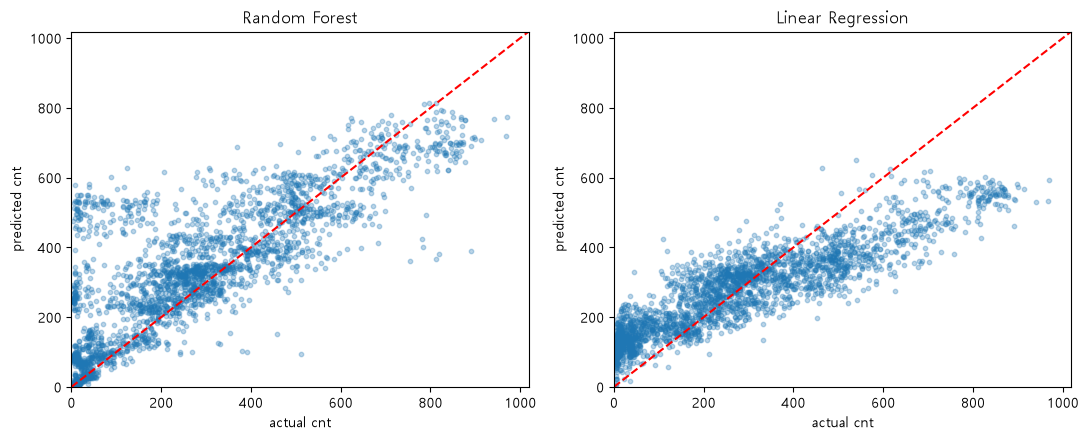

In [33]:
# [공통] 두 후보 모델을 나란히 비교합니다.
assert len(candidates) == 2, "오류 분석 후보를 2개 선택하세요."
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
lim = pred_df["actual"].max() * 1.05

for ax, name in zip(axes, candidates):
    # TODO 7-3. 실제값(x), 예측값(y) 산점도와 y=x 기준선을 작성합니다.
    ax.scatter(pred_df["actual"], pred_df[f"pred_{name}"], s=10, alpha=0.3)  # 실제값과 예측값을 점으로 표시
    ax.plot([0, lim], [0, lim], color="red", linestyle="--")  # 실제값과 예측값이 같은 기준선

    # [공통] 축 및 제목
    ax.set_xlabel("actual cnt")
    ax.set_ylabel("predicted cnt")
    ax.set_title(name)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)

plt.tight_layout()
plt.show()

**그래프 해석:** 선형 회귀는 실제 대여량이 많은 구간에서 기준선 아래에 점이 많이 모여 과소 예측하는 경향을 보였다.\
랜덤 포레스트는 대여량이 많은 구간을 더 잘 따라갔지만, 실제 대여량이 적을 때도 수백 대로 과대 예측한 사례가 있었다.

### ⑦-3. 시간대별 MAE — TODO

**확인할 점:** 앞에서 확인한 몇 건의 오차가 다른 날짜의 같은 시간대에서도 비슷한지 살펴본다.

**방법:** 각 잔차의 절댓값을 구하고, Validation 기록을 시각(`hr`)별로 묶어 평균을 낸다. 같은 시각의 두 모델을 표와 막대그래프로 비교한다.

In [34]:
# [공통] 시간대별 오류 DataFrame
hourly_mae = pd.DataFrame(index=range(24))
hourly_mae.index.name = "hr"

for name in candidates:
    # TODO 7-4. 모델별 절대오차와 시간대별 평균 절대오차를 계산합니다.
    abs_err = pred_df[f"resid_{name}"].abs()
    hourly_mae[name] = abs_err.groupby(pred_df["hr"]).mean()

display(hourly_mae.round(1))

,Random Forest,Linear Regression
hr,,
0,95.1,70.6
1,115.5,89.7
2,117.2,94.2
3,172.7,99.5
4,112.3,101.3
5,118.5,95.0
6,96.2,76.0
7,105.4,126.4
8,121.3,188.1


**표 읽기:** 각 행은 같은 시각의 검증 기록을 모은 결과다.\
17시 MAE는 랜덤 포레스트 117.2대, 선형 회귀 195.8대로 랜덤 포레스트가 낮았다.\
3시에는 랜덤 포레스트 172.7대, 선형 회귀 99.5대로 순서가 바뀌었다.

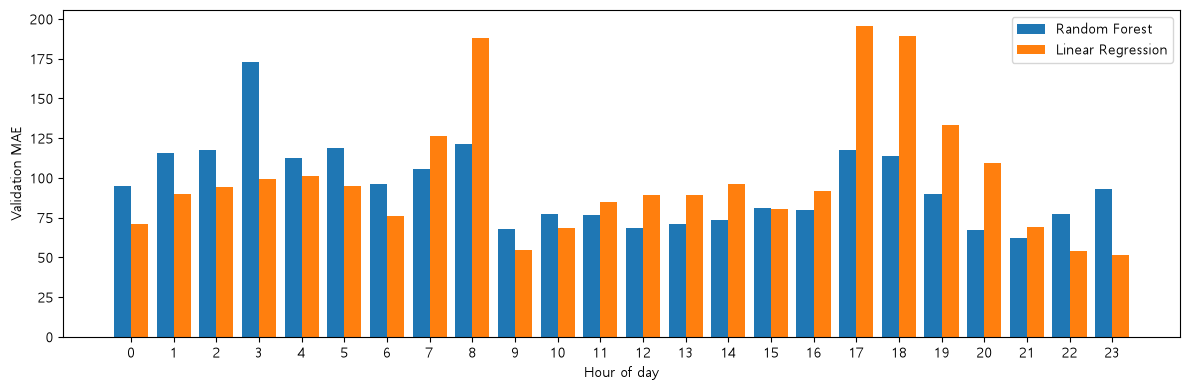

In [35]:
# TODO 7-5. 후보 모델들의 시간대별 MAE를 막대그래프로 표현합니다.
# 힌트: plt.bar(), hourly_mae
hours = hourly_mae.index.to_numpy()
width = 0.8 / len(hourly_mae.columns)
fig, ax = plt.subplots(figsize=(12, 4))
for i, name in enumerate(hourly_mae.columns):
    offset = (i - (len(hourly_mae.columns) - 1) / 2) * width
    ax.bar(hours + offset, hourly_mae[name], width=width, label=name)

ax.set_xticks(hours)
ax.set_xlabel("Hour of day")
ax.set_ylabel("Validation MAE")
ax.legend()
fig.tight_layout()
plt.show()

**그래프 해석:** 0~6시에는 선형 회귀의 막대가 모두 낮았다. 반면 8시와 17~19시에는 랜덤 포레스트의 오차가 더 작았다.\
막대 높이는 오차의 크기를 보여준다. 과대 예측인지 과소 예측인지는 잔차나 산점도로 확인한다.

### ⑦-4. 최종 모델 선택 — 기록

**선택 기준:** 실험의 주 지표인 Validation MAE를 먼저 보고, Validation RMSE와 시간대별 오차로 선택의 한계를 확인한다.

In [36]:
# **TODO 7-6:** results_df의 Validation MAE, Train, Validation 성능 차이, 예측 오류 분석 결과를 비교하여 최종 모델과 설정을 선택합니다.
# 선택한 모델과 그 근거는 adr.md의 의사결정 ②에 기록합니다.
# 선택한 모델과 설정은 ⑧교시의 최종 학습에 사용합니다.

selected_model_name = "Random Forest"  # 검증 MAE를 기준으로 선택
print("최종 모델:", selected_model_name)

최종 모델: Random Forest


**선택 근거:** 트리 200개, 깊이 제한 없음은 실험한 17개 설정 중 검증 MAE가 94.532대로 가장 낮았다.\
MAE 2위인 트리 200개, 깊이 20과는 0.226대 차이였으므로, 이번 검증 기간과 실험 범위에서 가장 좋았다고 해석한다.\
선형 회귀는 검증 RMSE가 더 낮고 새벽 시간대에 강했지만, 검증 MAE를 우선해 랜덤 포레스트를 골랐다. 최종 입력 특성은 아래 추가 실험에서 정한다.

**[CP-07] 완료 기준:** 잔차와 시간대별 MAE 분석을 완료하고 최종 모델 선택 이유를 설명합니다.

**선택 심화:** Permutation Importance로 입력 특성의 기여도를 분석합니다 (필수 아님).

**방법:** 검증 데이터에서 특성 하나의 값만 무작위로 섞고, 원래 예측보다 MAE가 얼마나 늘어나는지 비교한다. MAE가 많이 늘어난 특성은 이 모델의 예측에 더 많이 쓰였을 가능성이 있다.

In [37]:
# [선택 심화] 특성 중요도
# TODO (선택): sklearn.inspection.permutation_importance 를 사용해
# Validation 데이터에서 각 입력 특성을 섞었을 때 MAE가 얼마나 변하는지 분석합니다.
# 이 셀을 실행하지 않아도 ⑧교시 진행에 영향이 없습니다.

from sklearn.inspection import permutation_importance

importance_result = permutation_importance(
    candidates["Random Forest"],
    X_valid,
    y_valid,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
)

importance_table = pd.DataFrame({
    "입력 특성": X_valid.columns,
    "평균 MAE 증가량": importance_result.importances_mean,
    "증가량 표준편차": importance_result.importances_std,
}).sort_values("평균 MAE 증가량", ascending=False, ignore_index=True)

display(importance_table.round(3))

,입력 특성,평균 MAE 증가량,증가량 표준편차
0,is_commute_hour,77.243,1.833
1,hr,60.763,1.006
2,atemp,20.991,0.965
3,workingday,11.478,0.762
4,hum,8.802,0.769
5,weekday,1.838,0.442
6,weathersit,1.791,0.397
7,season,0.225,0.024
8,holiday,0.098,0.044
9,mnth,0.011,0.039


**결과 해석**

- 출퇴근 여부(`is_commute_hour`)를 섞었을 때 검증 MAE가 평균 **77.243대** 늘어 가장 큰 변화가 나타났다. 시간대(`hr`)는 **60.763대**, 체감온도(`atemp`)는 **20.991대** 늘었다.
- 출퇴근 여부는 시간대와 근무일 여부로 만든 특성이다. 셋이 일부 정보를 공유하므로 각 증가량을 더해 전체 기여도로 해석하기는 어렵다.
- 기온과 풍속을 섞었을 때는 이번 검증 데이터에서 MAE가 조금 줄었다. 특성을 제거하는 효과는 그 특성을 뺀 상태로 다시 학습한 뒤 같은 검증 데이터에서 비교해야 알 수 있다.

### CP-07 추가 실험 — 출퇴근 특성의 효과

시간대와 근무일 여부가 이미 있어도, 둘을 합쳐 만든 출퇴근 특성이 예측에 도움이 되는지 확인한다.
기존 랜덤 포레스트와 출퇴근 특성만 빼고 같은 설정으로 다시 학습한 모델을 같은 검증 데이터에서 비교한다.

In [38]:
# CP-07 추가 실험: 출퇴근 특성 포함 여부 비교
from sklearn.base import clone

rf_with_commute = candidates["Random Forest"]
rf_without_commute = clone(rf_with_commute)
prep_without_commute = rf_without_commute.named_steps["preprocessor"]

# 전처리 대상과 입력 데이터에서 출퇴근 특성만 제외한다.
transformers_without_commute = [
    (name, transformer, [column for column in columns if column != "is_commute_hour"])
    for name, transformer, columns in prep_without_commute.transformers
]
prep_without_commute.set_params(transformers=transformers_without_commute)
X_train_without_commute = X_train.drop(columns="is_commute_hour")
X_valid_without_commute = X_valid.drop(columns="is_commute_hour")

rf_without_commute.fit(X_train_without_commute, y_train)

commute_comparison = pd.DataFrame({
    "출퇴근 특성 포함": evaluate_regression(rf_with_commute, X_valid, y_valid),
    "출퇴근 특성 제외": evaluate_regression(rf_without_commute, X_valid_without_commute, y_valid),
}).T

display(commute_comparison.round(3))

,MAE,RMSE,R2
출퇴근 특성 포함,94.532,142.248,0.593
출퇴근 특성 제외,86.194,125.382,0.684


**결과 해석**

- 출퇴근 특성을 빼고 다시 학습했을 때 검증 MAE가 **94.532대 → 86.194대**로 약 **8.34대** 줄었다. RMSE도 **142.248대 → 125.382대**로 낮아졌다.
- 특성 중요도 실험은 이미 학습한 모델에 출퇴근 여부를 섞어 넣었을 때 오차가 얼마나 늘어나는지 봤다. 이번에는 그 열을 뺀 채 다시 학습했으므로, 모델은 남아 있는 시간대와 근무일 정보로 다른 예측 규칙을 배울 수 있었다.
- 같은 설정과 이번 검증 기간에서는 출퇴근 특성을 제외한 쪽이 더 정확했다. 이 검증 결과를 기준으로 출퇴근 특성을 제외한 설정을 CP-08에 사용한다.

### CP-07 추가 실험 1 — 최종 설정의 시간대별 오류

**문제:** 출퇴근 특성을 제외한 모델의 전체 검증 MAE는 낮아졌지만, 모든 시간대에서 개선됐는지 확인해야 한다.

**방법:** 같은 Validation에서 출퇴근 특성 포함 모델과 제외 모델의 시간대별 MAE를 비교한다. 차이(제외-포함)가 음수이면 제외 모델의 오차가 더 작다.


In [ ]:
# CP-07 추가 실험 1: 출퇴근 특성 포함 여부에 따른 시간대별 검증 MAE
valid_hourly_compare = pd.DataFrame({
    "hour": X_valid["hr"].to_numpy(),
    "포함": np.abs(y_valid.to_numpy() - rf_with_commute.predict(X_valid)),
    "제외": np.abs(y_valid.to_numpy() - rf_without_commute.predict(X_valid_without_commute)),
}).groupby("hour")[["포함", "제외"]].mean()
valid_hourly_compare["차이(제외-포함)"] = valid_hourly_compare["제외"] - valid_hourly_compare["포함"]
display(valid_hourly_compare.round(2))
print("제외 모델의 오차가 낮은 시간대:", (valid_hourly_compare["차이(제외-포함)"] < 0).sum(), "/ 24")


          포함      제외  차이(제외-포함)
hour                           
0      95.06   67.90     -27.16
1     115.52   86.15     -29.37
2     117.24   88.89     -28.35
3     172.69  134.73     -37.95
4     112.25   89.41     -22.84
5     118.52   91.47     -27.05
6      96.20   74.35     -21.85
7     105.39  133.83      28.44
8     121.32  170.73      49.41
9      67.68   73.11       5.44
10     77.20   62.85     -14.35
11     76.29   60.20     -16.09
12     68.44   55.47     -12.97
13     70.64   55.88     -14.75
14     73.37   55.71     -17.67
15     80.82   68.13     -12.70
16     79.51   76.94      -2.57
17    117.24  118.05       0.80
18    113.84  114.92       1.08
19     90.09   93.98       3.89
20     67.12   80.82      13.70
21     61.81   67.56       5.75
22     77.42   73.21      -4.22
23     93.09   74.36     -18.74
제외 모델의 오차가 낮은 시간대: 16 / 24


**결과 해석:** 출퇴근 특성을 제외한 모델은 24개 시간대 중 16개에서 MAE가 낮았다. 예를 들어 3시는 172.69대에서 134.73대로 낮아졌지만, 8시는 121.32대에서 170.73대로 높아졌다.

**판단:** 전체 MAE가 줄어도 모든 시간대가 개선된 것은 아니다. 이 비교는 Train으로 학습한 두 설정의 기존 Validation 결과이며, Train과 Validation을 합쳐 재학습한 최종 모델의 Test 시간대별 성능은 아니다.


### CP-07 추가 실험 2 — 다른 기간에서 출퇴근 특성 비교

**문제:** 출퇴근 특성을 제외한 효과가 기존 Validation 기간에서만 나타났는지 확인한다.

**방법:** 기존 Train의 날짜를 기준으로 3회 확장형 시간순 검증을 수행한다. 각 회차에서 과거 날짜로 학습하고 이어지는 날짜로 검증하며, 같은 데이터와 랜덤 포레스트 설정에서 출퇴근 특성 포함과 제외를 비교한다. 전처리는 매 회차의 학습 데이터에서만 학습하고 기존 Validation과 Test는 이 추가 검증에 사용하지 않는다.


In [ ]:
# CP-07 추가 실험 2: Train 기간 안에서 날짜 단위 확장형 시간순 검증
from sklearn.model_selection import TimeSeriesSplit

train_dates_cv = np.sort(train_df["dteday"].unique())
cv = TimeSeriesSplit(n_splits=3)
period_results = []
for fold, (train_date_idx, valid_date_idx) in enumerate(cv.split(train_dates_cv), start=1):
    cv_train_dates = train_dates_cv[train_date_idx]
    cv_valid_dates = train_dates_cv[valid_date_idx]
    fit_mask = train_df["dteday"].isin(cv_train_dates).to_numpy()
    check_mask = train_df["dteday"].isin(cv_valid_dates).to_numpy()
    row = {"회차": fold, "학습 기간": f"{pd.Timestamp(cv_train_dates[0]):%Y-%m-%d} ~ {pd.Timestamp(cv_train_dates[-1]):%Y-%m-%d}", "검증 기간": f"{pd.Timestamp(cv_valid_dates[0]):%Y-%m-%d} ~ {pd.Timestamp(cv_valid_dates[-1]):%Y-%m-%d}"}
    for label, model, features in [("포함 MAE", rf_with_commute, X_train), ("제외 MAE", rf_without_commute, X_train_without_commute)]:
        cv_model = clone(model)
        cv_model.fit(features.iloc[fit_mask], y_train.iloc[fit_mask])
        row[label] = mean_absolute_error(y_train.iloc[check_mask], cv_model.predict(features.iloc[check_mask]))
    row["차이(제외-포함)"] = row["제외 MAE"] - row["포함 MAE"]
    period_results.append(row)
period_compare = pd.DataFrame(period_results).set_index("회차")
display(period_compare.round(3))
print("3회 평균 MAE:", period_compare[["포함 MAE", "제외 MAE"]].mean().round(3).to_dict())


                      학습 기간                    검증 기간  포함 MAE  제외 MAE  차이(제외-포함)
회차                                                                             
1   2011-01-01 ~ 2011-05-10  2011-05-11 ~ 2011-09-14  76.136  75.932     -0.204
2   2011-01-01 ~ 2011-09-14  2011-09-15 ~ 2012-01-19  53.968  52.404     -1.564
3   2011-01-01 ~ 2012-01-19  2012-01-20 ~ 2012-05-25  75.555  76.368      0.813
3회 평균 MAE: {'포함 MAE': 68.553, '제외 MAE': 68.235}


**결과 해석:** 제외 모델의 MAE는 1회차 76.136대 → 75.932대, 2회차 53.968대 → 52.404대로 낮아졌지만, 3회차에는 75.555대 → 76.368대로 높아졌다. 세 회차의 단순 평균은 포함 68.553대, 제외 68.235대다.

**판단:** 제외 모델이 3회 중 2회에서 낮았으나 평균 차이는 약 0.318대로 작고, 기존 Validation의 약 8.338대 개선이 매 기간 반복되지는 않았다. 회차별 학습 데이터가 겹치고 검증 기간도 세 개뿐이므로 일반적인 우위를 확정할 수 없다. 기존 최종 모델과 Test 결과는 유지하고, 이 결과는 선택의 안정성을 살펴본 추가 검증으로 기록한다.


---
## ⑧ 최종 모델 완성 및 예측 — CP-08

**문제:** 선택한 모델을 처음 보는 기간에서 평가하고, 저장한 모델로 새 입력 한 건도 예측할 수 있게 한다.

### ⑧-1. 최종 모델 재학습 — TODO

**방법:** `clone()`으로 CP-07의 출퇴근 특성 제외 Pipeline 설정을 복사해 새 모델을 만든다. Train과 Validation을 합친 14,755개 기록으로 전처리와 모델을 함께 다시 학습한다.

In [39]:
import joblib
from sklearn.base import clone
from pathlib import Path

# [공통] Train과 Validation 데이터 결합
X_trainval = pd.concat([X_train_without_commute, X_valid_without_commute])
y_trainval = pd.concat([y_train, y_valid])

# TODO 8-1. ⑦에서 선택한 모델과 하이퍼파라미터로 새 estimator를 생성합니다.
# 예: 앞서 사용한 회귀 모델 클래스와 선택한 설정을 사용합니다.
# [공통] 최종 Pipeline은 전처리를 포함해야 합니다.
final_model = clone(rf_without_commute)

# TODO 8-2. Train + Validation으로 최종 모델을 재학습합니다.
final_model.fit(X_trainval, y_trainval)
print("최종 모델 학습 완료")

최종 모델 학습 완료


**결과 해석:** `최종 모델 학습 완료`가 출력되면, 선택한 설정으로 합친 데이터의 전처리와 모델 학습이 끝난 것이다.\
새로운 기간에서 얼마나 잘 예측하는지는 다음 Test 평가에서 확인한다.

### ⑧-2. Test 평가 — TODO

**방법:** 모델을 선택하고 재학습한 뒤, 별도로 남겨 둔 Test 2,624건에서 MAE, RMSE, R²를 계산한다. 세 지표는 CP-04에서 사용한 평가 함수로 계산한다.

In [40]:
# TODO 8-3. Test 데이터에 대해 최종 MAE, RMSE, R2를 평가합니다.
# ④에서 작성한 evaluate_regression()을 재사용합니다.
X_test_without_commute = X_test.drop(columns="is_commute_hour")
test_scores = evaluate_regression(final_model, X_test_without_commute, y_test)
print("최종 Test 성능:", test_scores)

최종 Test 성능: {'MAE': 54.11815240726626, 'RMSE': 81.48500429765363, 'R2': 0.8564812586782959}


**결과 해석:** 출퇴근 특성을 제외한 모델의 Test MAE는 54.12대였다. 시간당 예측값과 실제값이 평균 약 54대 차이 났다.\
RMSE는 81.49대, R²는 0.856였다.\
같은 Test에서 앞서 확인한 포함 모델의 MAE는 58.23대였다. 입력 특성 선택에는 CP-07의 검증 MAE를 사용했다.

### ⑧-3. 최종 모델 저장과 재로딩 — TODO

**방법:** `joblib`으로 전처리와 모델을 하나의 Pipeline 파일에 저장하고 다시 불러온다. Test의 첫 100건을 원래 모델과 재로딩한 모델에 각각 입력해, `np.allclose()`로 예측값이 허용 오차 안에서 같은지 확인한다.

In [41]:
# [공통] 결과 폴더와 저장 경로
RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(exist_ok=True)
MODEL_PATH = RESULTS_DIR / "01_final_model.joblib"

# TODO 8-4. 전처리+모델 Pipeline을 joblib으로 저장합니다 (compress=3).
joblib.dump(final_model, MODEL_PATH, compress=3)

# TODO 8-5. 저장된 Pipeline을 다시 불러옵니다.
loaded_model = joblib.load(MODEL_PATH)

# TODO 8-6. 저장 전후 예측 결과가 일치하는지 확인합니다.
# 힌트: np.allclose(), X_test.iloc[:100]
check_rows = X_test_without_commute.iloc[:100]
same_pred = np.allclose(final_model.predict(check_rows), loaded_model.predict(check_rows))
print("저장 전후 예측 일치:", same_pred)

저장 전후 예측 일치: True


**결과 해석:** `True`는 확인한 Test 첫 100건에서 저장 전과 재로딩 후의 예측이 허용 오차 안에서 일치했다는 뜻이다.\
`01_final_model.joblib`에는 학습한 전처리와 랜덤 포레스트가 함께 들어 있다.

In [42]:
# [공통] 실험 결과표 저장
results_df.round(3).to_csv(
    RESULTS_DIR / "01_model_comparison.csv", index=False
)
hourly_mae.round(2).to_csv(
    RESULTS_DIR / "01_hourly_mae_validation.csv"
)
print("결과 파일:", sorted(p.name for p in RESULTS_DIR.iterdir()))

결과 파일: ['.gitkeep', '01_final_model.joblib', '01_hourly_mae_validation.csv', '01_model_comparison.csv']


**저장 결과:** `01_model_comparison.csv`에는 설정별 비교 점수가, `01_hourly_mae_validation.csv`에는 두 후보의 시간대별 검증 MAE가 저장됐다.\
모델을 고른 근거와 시간대별 차이를 다시 확인할 때 사용한다.

### ⑧-4. 단일 입력 예측 함수 — TODO

**방법:** 시간, 날씨 등을 최종 학습에 사용한 12개 기본 특성으로 구성한다. 저장한 Pipeline으로 예측한 대여량을 반올림해 정수로 반환한다.

**입력 단위:** 기온, 체감온도, 습도, 풍속은 학습 데이터와 같은 정규화 단위를 사용한다. 예제의 섭씨 20도는 함수로 변환하고, 체감온도는 정규화된 예시 값 `0.45`를 넣는다.

In [43]:
def predict_demand(
    model, season, yr, mnth, hr, holiday,
    weekday, workingday, weathersit, temp, atemp, hum, windspeed
):
    """한 시간의 입력 조건으로 예상 대여량(정수)을 반환합니다.

    temp, atemp, hum, windspeed는 hour.csv와 같은 정규화 값(0~1)으로 입력합니다.
    """
    # TODO 8-7. 전달받은 값으로 입력 1행 DataFrame을 만듭니다.
    # 학습에 사용한 FEATURES 컬럼을 정확히 사용해야 합니다.
    row = pd.DataFrame([{
        "season": season,
        "yr": yr,
        "mnth": mnth,
        "hr": hr,
        "holiday": holiday,
        "weekday": weekday,
        "workingday": workingday,
        "weathersit": weathersit,
        "temp": temp,
        "atemp": atemp,
        "hum": hum,
        "windspeed": windspeed,
    }], columns=FEATURES)

    # TODO 8-8. ③에서 만든 동일한 특성공학 함수를 적용합니다.
    # CP-07에서 선택한 최종 모델은 위의 12개 기본 특성만 사용합니다.

    # TODO 8-9. 예측값 하나를 구해 정수로 반환합니다.
    pred = model.predict(row)[0]
    return int(round(pred))


# [공통] 섭씨 온도를 원본 데이터의 정규화 기온으로 변환
def celsius_to_temp(c):
    return (c + 8) / 47


# [공통] 예측 입력 예제
sample = {
    "season": 4,
    "yr": 1,
    "mnth": 10,
    "hr": 18,
    "holiday": 0,
    "weekday": 3,
    "workingday": 1,
    "weathersit": 1,
    "temp": celsius_to_temp(20),
    "atemp": 0.45,  # 정규화한 예시 체감온도
    "hum": 0.50,
    "windspeed": 0.15,
}

# TODO 8-10. 저장한 모델과 sample을 사용해 predict_demand()를 호출합니다.
# 힌트: predict_demand(loaded_model, **sample)
result = predict_demand(loaded_model, **sample)
print("예상 대여량:", result)

예상 대여량: 653


**결과 해석:** 예제의 10월 근무일 18시, 기온 20°C 조건에서 모델은 한 시간 동안 약 653대가 대여될 것으로 예측했다.\
이 값은 입력한 한 시간의 예상 대여량이며, 모델의 전체적인 오차는 앞서 계산한 Test 지표로 읽는다.

**[CP-08] 완료 기준 :** 최종 재학습, Test 평가, 모델 저장, 재로딩, 예측 함수가 정상 동작하면 프로젝트 코드가 완성됩니다.